# Ejercicio 4 desde cero: ubicar objetos en la cancha con una homografía

**Qué queremos:** a partir de una foto de la cancha, saber dónde está cada jugador **en metros**, y poder dibujar sobre la foto cosas definidas en metros (círculos de 1 m, una línea de offside).

**La idea en una línea:** la cancha es plana, así que la foto la deforma con **una sola matriz de 3×3, la `H`**.
* `H` lleva de **metros → píxeles**.
* `H⁻¹` (su inversa) lleva de **píxeles → metros**.

**El plan (9 pasos):**

| Paso | Qué hacemos | Cómo sabemos que salió bien |
|---|---|---|
| 0 | Preparar el entorno | `from alc import *` no da error |
| 1 | Entender qué hace `H` | (teoría) |
| 2 | Probar nuestras funciones con una `H` inventada | recuperamos la `H` inventada |
| 3 | Elegir los puntos de referencia de la foto 1 | cada número de la foto = mismo número del plano |
| 4 | Calcular `H` de la foto 1 y validarla | error de pocos píxeles y las líneas dibujadas calzan |
| 5 | **Inciso a)** distancia de Enzo a la línea del arco | número razonable (> 16,5 m) |
| 6 | **Inciso b)** círculos de 1 m en los argentinos | elipses alrededor de cada jugador |
| 7 | **Inciso c)** foto 2: otra `H`, recta de offside | recta inclinada que pasa por el último defensor |
| 8 | Resumen y límites | |

## Paso 0: preparar el entorno

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from alc_ej4 import *                    
np.set_printoptions(precision=4, suppress=True)

 
FOTO_ENZO = 'futbol/test-gol-enzo.png'
FOTO_OFF = 'futbol/test-fuera-de-juego.png'

def valores_singulares(Q):
    """Valores singulares de Q (de mayor a menor) con nuestra svd_reducida.
    tol = -1 para que no descarte ninguno (incluso el casi nulo)."""
    U, S, V = svd_reducida(Q, "max", -1.0)
    return S

## Paso 1: qué hace `H` (la teoría que hay que tener clara)

Un punto del piso `(U, V)` (en metros) se ve en la foto en el píxel `(u, v)` según

$$\lambda\begin{bmatrix}u\\v\\1\end{bmatrix}=H\begin{bmatrix}U\\V\\1\end{bmatrix},\qquad H\in\mathbb{R}^{3\times3}.$$

**Cómo se aplica `H` (la fórmula que más se usa):** se multiplica y **se divide por la tercera coordenada**:
$$\begin{bmatrix}a\\b\\c\end{bmatrix}=H\begin{bmatrix}U\\V\\1\end{bmatrix}\ \Rightarrow\ u=\frac ac,\quad v=\frac bc .$$
Esa división es la perspectiva. Si te la olvidás, el resultado sale mal.

**Cómo se encuentra `H` (DLT).** Con $\mathbf h_j^T$ la fila $j$ de $H$ y $P=(U,V,1)^T$, despejando $u$ y $v$:
$$(\mathbf h_1-u\,\mathbf h_3)^TP=0,\qquad(\mathbf h_2-v\,\mathbf h_3)^TP=0 .$$
Son ecuaciones **lineales** en las 9 entradas de $H$. Cada punto aporta 2 filas a una tabla $Q$ (de $2n\times9$) y queda $Q\mathbf h=0$. Con ruido en los clics no hay solución exacta, así que se minimiza $\|Q\mathbf h\|^2$ con $\|\mathbf h\|=1$. Eso es **exactamente el ejercicio 1b** (mínimos cuadrados homogéneos con restricción de norma): con la SVD $Q=U\Sigma V^T$, la solución es la columna de $V$ asociada al **menor valor singular** (el error $\|Q\mathbf h\|$ vale justo ese $\sigma$). Es el mismo vector que el autovector de menor autovalor de $Q^TQ$, porque $Q^TQ=V\Sigma^2V^T$.

**Cuántos puntos:** $H$ tiene 8 grados de libertad (se define salvo escala), así que hacen falta $n\ge4$ puntos, sin tres alineados (rango de $Q$ = 8). Conviene usar más para promediar el error de los clics.

**Relación con el ejercicio 2:** es el mismo método con $W=0$; $H$ son las columnas 1, 2 y 4 de $M$.

## Paso 2: probar nuestras funciones con una `H` inventada

Antes de tocar las fotos comprobamos que el código funciona **cuando conocemos la respuesta**: inventamos una `H`, "fotografiamos" unos puntos con ella y vemos si `estimar_homografia` la recupera. También probamos la ida y vuelta con `H⁻¹`.

In [20]:
H_inventada = np.array([[1.2, 0.3, 300.0],
                        [-0.1, 0.8, 200.0],
                        [0.001, 0.002, 1.0]])
metros  = np.array([[0, 0], [10, 0], [10, 5], [0, 5], [5, 2.5], [3, 4], [8, 1]], dtype=float)
pixeles = aplicar_homografia(H_inventada, metros)         # "fotografiamos" los puntos
H_recuperada = estimar_homografia(pixeles, metros)        # ¿la recupera nuestro DLT?

print("H inventada:\n", H_inventada)
print("H recuperada:\n", H_recuperada)
print("máxima diferencia: %.2e   (debe ser ~1e-10 o menos)" % np.max(np.abs(H_inventada - H_recuperada)))

# ida y vuelta: metros -> píxeles -> metros con la inversa
vuelta = aplicar_homografia(inversa(H_recuperada), pixeles)
print("ida y vuelta (metros -> píxeles -> metros), error máximo: %.2e" % np.max(np.abs(vuelta - metros)))

H inventada:
 [[  1.2     0.3   300.   ]
 [ -0.1     0.8   200.   ]
 [  0.001   0.002   1.   ]]
H recuperada:
 [[  1.2     0.3   300.   ]
 [ -0.1     0.8   200.   ]
 [  0.001   0.002   1.   ]]
máxima diferencia: 2.55e-13   (debe ser ~1e-10 o menos)
ida y vuelta (metros -> píxeles -> metros), error máximo: 2.15e-13


En primer lugar vamos a elegir los puntos de referencia de la foto 1 (gol de Enzo)

**Sistema de la cancha** (`estadio_azteca.png`): `U` = distancia a la línea de fondo, `V` = ancho, ambos en metros. El arco de la foto está en `U = 0`. Mirando hacia el arco, **la izquierda de la imagen es `V` chico**.

**Los criterios que elegimos para los puntos fueron:**
1. Que se vean sin dudas en la foto (intersecciones de líneas, esquinas, pie de los palos).
2. Que tengan medidas reglamentarias conocidas.
3. Que estén repartidos por toda la imagen y **no alineados**.
4. Que rodeen la zona donde están los jugadores.

En total elegimos 8 puntos: las 4 esquinas del área chica (5,5 m × 18,32 m), los 2 puntos donde el arco del área corta la línea del área grande (16,5 m) y los pies de los 2 palos (7,32 m de arco).
Como $H$ tiene 8 grados de libertad, hacen falta $n\ge4$ puntos, sin tres alineados (rango de $Q$ = 8). Usamos 8 para promediar el error de los clics.

**Píxeles:** `u` es la **columna** y `v` es la **fila** (origen arriba a la izquierda). Se marcan a mano con zoom.

Herramienta que usamos **solo para medir** los píxeles (no forma parte del código entregado, `ginput` no está entre las funciones permitidas):
```python
%matplotlib qt
plt.figure(figsize=(14, 9)); plt.imshow(foto)
clics = plt.ginput(n=8, timeout=0)     # clic en los 8 puntos, en el mismo orden que la lista de metros
print(clics)
```

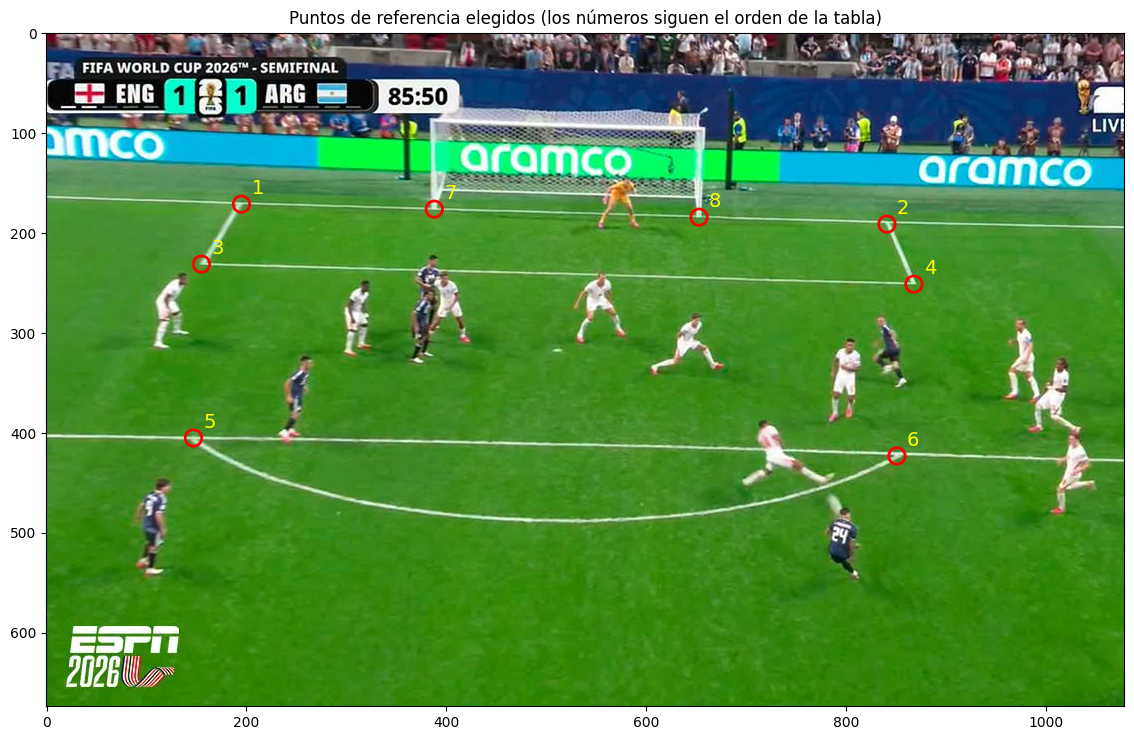

In [21]:
# ----------------- Primer foto: gol de Enzo -----------------
# Sistema de la cancha (estadio_azteca.png): U = largo (0..105 m), V = ancho (0..68 m); el arco de la foto está en U = 0.
# Cada fila: (U, V) en metros  <->  (u, v) en píxeles de la foto (u = columna, v = fila, origen arriba a la izquierda).
# Medidos sobre test-gol-enzo.png (1079x674) y verificados dibujándolos sobre la foto (caen sobre las esquinas).
referencias_enzo = [
    # U      V      u    v
    (0.0,   24.84, 195, 171),   # esquina del área chica sobre la línea de fondo (izquierda de la imagen)
    (0.0,   43.16, 841, 191),   # esquina del área chica sobre la línea de fondo (derecha)
    (5.5,   24.84, 155, 231),   # esquina del área chica, lado de adelante (izquierda)
    (5.5,   43.16, 868, 251),   # esquina del área chica, lado de adelante (derecha)
    (16.5,  26.69, 147, 405),   # donde el arco del área corta la línea del área grande (izquierda)
    (16.5,  41.31, 851, 423),   # donde el arco del área corta la línea del área grande (derecha)
    (0.0,   30.34, 388, 176),   # pie del palo izquierdo
    (0.0,   37.66, 653, 184),   # pie del palo derecho
]
tabla = np.array(referencias_enzo)
obj_enzo = tabla[:, 0:2]        # metros
img_enzo = tabla[:, 2:4]        # píxeles


foto_enzo = mpimg.imread(FOTO_ENZO)
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(foto_enzo)
for i in range(tabla.shape[0]):
    ax.scatter([tabla[i, 2]], [tabla[i, 3]], s=140, facecolors='none', edgecolors='red', linewidths=2)
    ax.text(tabla[i, 2] + 10, tabla[i, 3] - 10, str(i + 1), color='yellow', fontsize=14)
ax.set_title("Puntos de referencia elegidos (los números siguen el orden de la tabla)")
plt.tight_layout()
plt.show()

Luego, vamos a calcular `H` de la foto 1 con la función`estimar_homografia` que lo hace por dentro es: normalizar los puntos → armar $Q$ → obtener autovector de menor autovalor de $Q^TQ$ → deshacer la normalización.


In [22]:
# ----------------- FOTO 1: gol de Enzo -----------------
# Sistema de la cancha (estadio_azteca.png): U = largo (0..105 m), V = ancho (0..68 m); el arco de la foto está en U = 0.
# Cada fila: (U, V) en metros  <->  (u, v) en píxeles de la foto (u = columna, v = fila, origen arriba a la izquierda).
referencias_enzo = [
    # U      V      u    v
    (0.0,   24.84, 195, 171),   # esquina del área chica sobre la línea de fondo (izquierda de la imagen)
    (0.0,   43.16, 841, 191),   # esquina del área chica sobre la línea de fondo (derecha)
    (5.5,   24.84, 155, 231),   # esquina del área chica, lado de adelante (izquierda)
    (5.5,   43.16, 868, 251),   # esquina del área chica, lado de adelante (derecha)
    (16.5,  26.69, 147, 405),   # donde el arco del área corta la línea del área grande (izquierda)
    (16.5,  41.31, 851, 423),   # donde el arco del área corta la línea del área grande (derecha)
    (0.0,   30.34, 388, 176),   # pie del palo izquierdo
    (0.0,   37.66, 653, 184),   # pie del palo derecho
]
tabla = np.array(referencias_enzo)
obj_enzo = tabla[:, 0:2]        # metros
img_enzo = tabla[:, 2:4]        # píxeles

H_enzo = estimar_homografia(img_enzo, obj_enzo)
print("H (cancha -> foto), H[2,2]=1:\n", H_enzo)
print("Error de reproyección (RMS): %.2f px" % error_reproyeccion(H_enzo, img_enzo, obj_enzo))

# ¿Para qué sirve Hartley? Comparamos el condicionamiento de Q (valor singular mayor / menor) con y sin normalizar
img_n, _ = normalizar_puntos(img_enzo)
obj_n, _ = normalizar_puntos(obj_enzo)
for texto, a, b in [("sin Hartley", img_enzo, obj_enzo), ("con Hartley", img_n, obj_n)]:
    try:
        sv = valores_singulares(armar_Q(a, b))
        print("%-12s valor singular mayor / menor de Q = %.1e" % (texto, sv[0] / sv[-1]))
    except TypeError as e:
        print("%-12s no se pudo calcular: %s" % (texto, e))

H (cancha -> foto), H[2,2]=1:
 [[  -9.5409   37.3029 -727.9775]
 [   7.7745    1.3329  141.455 ]
 [  -0.0167    0.0011    1.    ]]
Error de reproyección (RMS): 2.01 px
sin Hartley  valor singular mayor / menor de Q = 9.8e+06
con Hartley  valor singular mayor / menor de Q = 3.3e+02


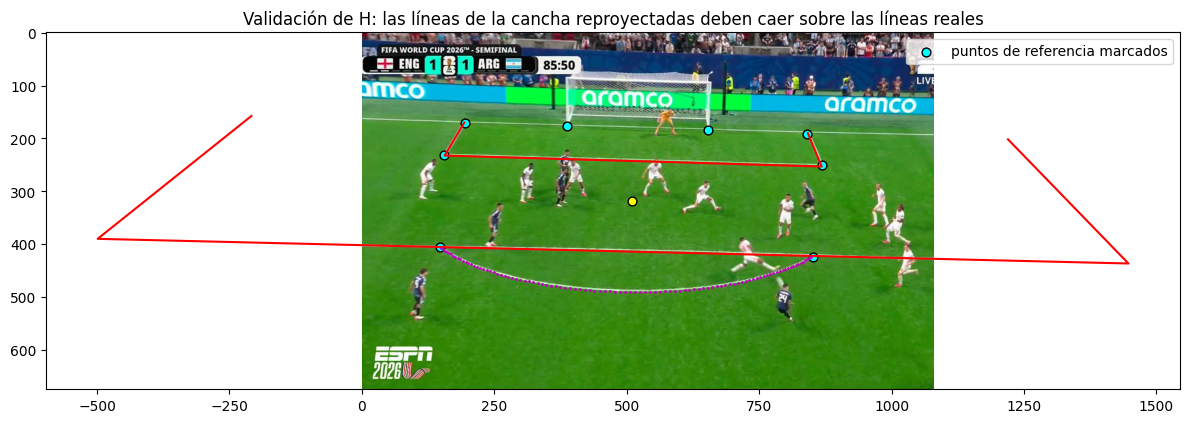

In [23]:
def dibujar_cancha(H, ax, color='r'):
    """Dibuja sobre la foto las líneas de la cancha (definidas en metros) proyectadas con H, para VALIDAR H."""
    def trazo(puntos):
        p = aplicar_homografia(H, np.array(puntos))
        ax.plot(p[:, 0], p[:, 1], color + '-', linewidth=1.5)
    trazo([[0, 13.84], [16.5, 13.84], [16.5, 54.16], [0, 54.16]])             # área grande
    trazo([[0, 24.84], [5.5, 24.84], [5.5, 43.16], [0, 43.16]])               # área chica
    arco = circulo((11.0, 34.0), 9.15, 100)                                   # arco del área (radio 9,15 m desde el punto penal)
    lista = []
    for i in range(arco.shape[0]):
        if arco[i, 0] >= 16.5:
            lista.append([arco[i, 0], arco[i, 1]])
    p = aplicar_homografia(H, np.array(lista))
    ax.plot(p[:, 0], p[:, 1], 'm.', markersize=2)
    ps = aplicar_homografia(H, np.array([[11.0, 34.0]]))
    ax.scatter(ps[:, 0], ps[:, 1], s=40, c='yellow', edgecolors='k')          # punto penal

foto_enzo = mpimg.imread(FOTO_ENZO)
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(foto_enzo)
dibujar_cancha(H_enzo, ax)
ax.scatter(img_enzo[:, 0], img_enzo[:, 1], s=40, c='cyan', edgecolors='k', label='puntos de referencia marcados')
ax.set_title("Validación de H: las líneas de la cancha reproyectadas deben caer sobre las líneas reales")
ax.legend()
plt.tight_layout()
plt.show()

## Paso 5: inciso a) distancia de Enzo a la línea del arco

1. Marcamos el píxel del **pie de apoyo** de Enzo (la homografía solo vale para puntos **en el piso**).
2. Lo pasamos a la cancha: $(U,V)=\text{dehomogeneizar}(H^{-1}[u\ v\ 1]^T)$.
3. Como el arco está en $U=0$, la distancia a la línea del arco es $U$.

In [24]:
# ----------------- 4a) Distancia de Enzo a la línea del arco -----------------
pie_enzo = np.array([[809.0, 544.0]])                    # píxel del pie de apoyo de Enzo (camiseta 24)
H_inv = inversa(H_enzo)
pos = aplicar_homografia(H_inv, pie_enzo)                # foto -> cancha (en metros)
U, V = pos[0, 0], pos[0, 1]
print("Enzo en la cancha: U = %.2f m (distancia a la línea de fondo), V = %.2f m (a lo ancho)" % (U, V))
print("Distancia perpendicular a la línea del arco: %.2f m" % U)
print("Distancia en línea recta al centro del arco (0, 34): %.2f m" % np.sqrt(U ** 2 + (V - 34.0) ** 2))

# Sensibilidad: ¿cuánto cambia U si el clic se corre 3 píxeles?
valores = []
for du in (-3.0, 0.0, 3.0):
    for dv in (-3.0, 0.0, 3.0):
        q = aplicar_homografia(H_inv, np.array([[809.0 + du, 544.0 + dv]]))
        valores.append(q[0, 0])
print("Con un error de +-3 px en el clic, U varía entre %.2f m y %.2f m" % (np.min(np.array(valores)), np.max(np.array(valores))))

Enzo en la cancha: U = 22.15 m (distancia a la línea de fondo), V = 39.80 m (a lo ancho)
Distancia perpendicular a la línea del arco: 22.15 m
Distancia en línea recta al centro del arco (0, 34): 22.90 m
Con un error de +-3 px en el clic, U varía entre 22.03 m y 22.28 m


*(Valores calculados con la foto de prueba test-gol-enzo.png; si se cambia por otra imagen, volver a correr y actualizar.)*

**Resultado a).** Enzo está a ≈ **22,2 m** de la línea del arco (≈ 22,9 m al centro del arco). Es razonable: en la foto está por debajo de la línea del área grande (16,5 m) y apenas más lejos que la punta del arco del área (20,15 m). Con un error de ±3 px en el clic el valor varía entre 22,03 m y 22,28 m (unos ±0,13 m).

## Paso 6: inciso b) círculos de 1 m en los argentinos

1. Marcamos los pies de cada argentino (camiseta oscura) y los pasamos a metros con $H^{-1}$.
2. Definimos el círculo **en metros** alrededor de cada uno.
3. Proyectamos los puntos del círculo a la foto con $H$.

Se ve como una **elipse**: la perspectiva comprime la dirección de profundidad. Un círculo dibujado directamente en píxeles estaría mal, porque no representaría 1 m en el piso.

Posición de cada argentino en la cancha (U, V) en metros:
 [[22.1524 39.8015]
 [16.0734 28.5984]
 [22.3974 27.0554]
 [11.6156 31.0008]
 [12.0382 41.7354]
 [ 9.1481 30.9516]]


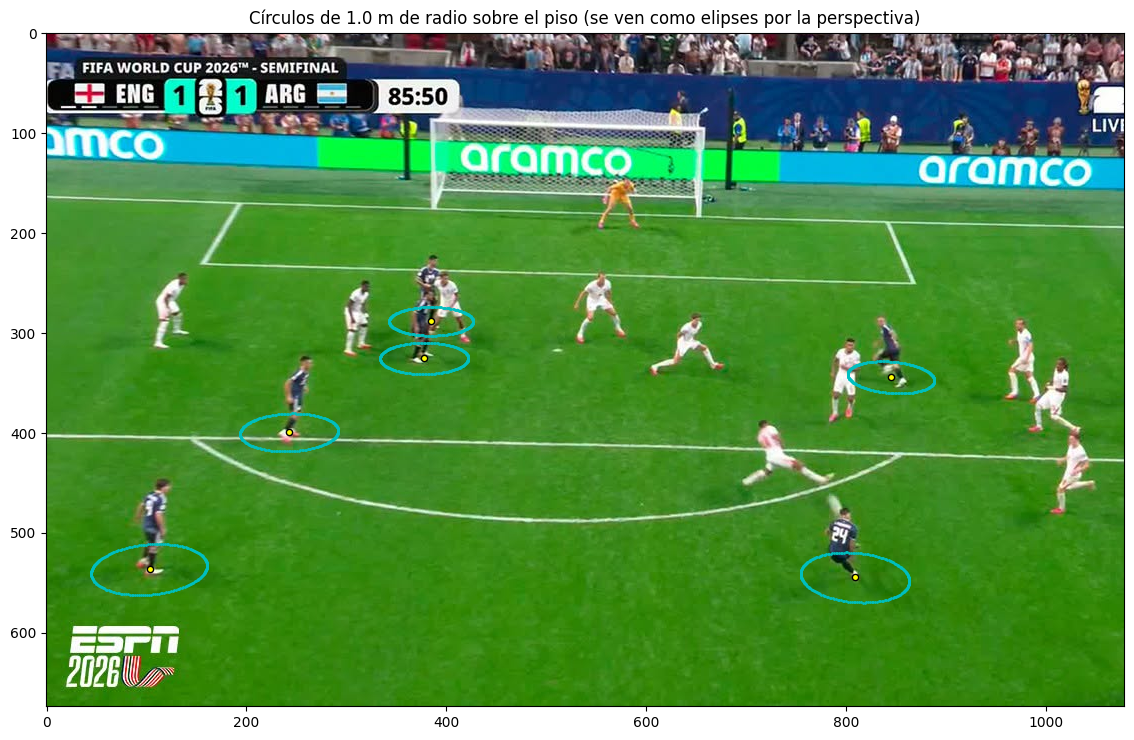

In [25]:
# ----------------- 4b) Círculos de 1 m alrededor de los argentinos -----------------
RADIO = 1.0     # el enunciado pide un círculo de 1 metro de RADIO
pies_argentinos = np.array([      # píxel del pie de cada jugador argentino (camiseta oscura)
    [809.0, 544.0],    # Enzo (24)
    [243.0, 399.0],    # jugador en el borde de la línea del área grande
    [103.0, 536.0],    # jugador abajo a la izquierda
    [378.0, 325.0],    # jugador junto a dos ingleses (centro-izquierda)
    [845.0, 344.0],    # jugador a la derecha, corriendo
    [385.0, 288.0],    # 6.º argentino (jugador entre dos ingleses, arriba): tiene los pies TAPADOS, posición ESTIMADA
])
centros = aplicar_homografia(H_inv, pies_argentinos)     # a metros
print("Posición de cada argentino en la cancha (U, V) en metros:\n", centros)

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(foto_enzo)
for i in range(centros.shape[0]):
    aro = circulo((centros[i, 0], centros[i, 1]), RADIO, 60)   # círculo definido en METROS
    aro_foto = aplicar_homografia(H_enzo, aro)                  # proyectado a la foto
    ax.plot(aro_foto[:, 0], aro_foto[:, 1], 'c.', markersize=2)
ax.scatter(pies_argentinos[:, 0], pies_argentinos[:, 1], s=20, c='yellow', edgecolors='k')
ax.set_title("Círculos de %.1f m de radio sobre el piso (se ven como elipses por la perspectiva)" % RADIO)
plt.tight_layout()
plt.show()

## Paso 7: inciso c) posible offside (otra foto, otra `H`)

La cámara es otra, así que hay que estimar **otra homografía** con puntos de referencia de esa foto. Acá hay que **identificar bien las líneas** antes de marcar (un error típico es confundir el arco del área con el círculo central): la línea casi vertical es la del área grande (16,5 m) y el arco es el arco del área.

Después: pasamos los pies de los jugadores a metros, el último defensor (penúltimo adversario, el arquero está más cerca de la línea de fondo) es el de menor $U$, y la recta de offside es $U=\text{cte}$ (paralela a la línea de fondo), proyectada con $H$.

Error de reproyección (RMS): 2.09 px
Chequeo independiente: el punto penal (11, 34) cae en el píxel (1015, 473) y en la foto se ve en ~(1007, 472)


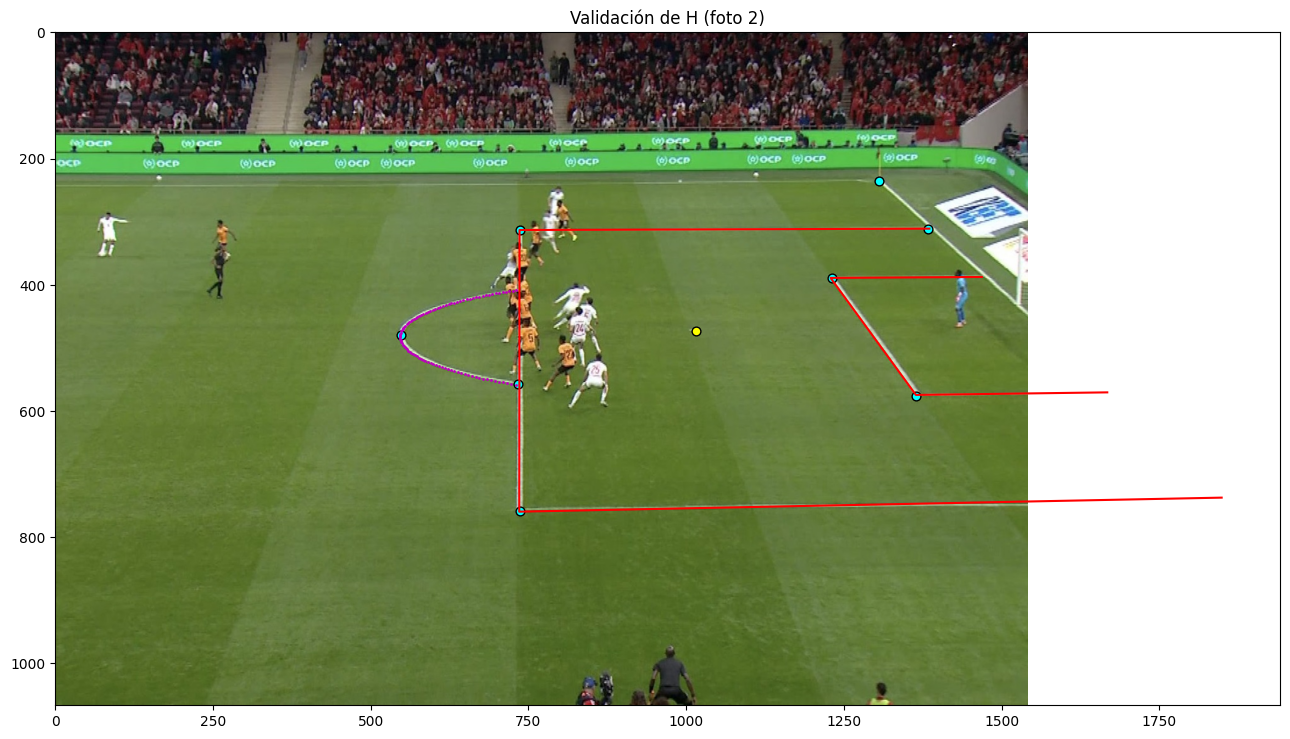

In [26]:
# ----------------- FOTO 2: posible offside (su propia homografía) -----------------
# Mismo sistema de la cancha: el arco de la foto está en U = 0; la banda más cercana a la cámara es V chico.
# Medidos sobre test-fuera-de-juego.png (1541x1067) y verificados dibujándolos sobre la foto.
referencias_off = [
    # U      V      u     v
    (16.5,  13.84,  736,  758),   # esquina cercana del área grande (línea del área con la línea lateral del área)
    (16.5,  54.16,  736,  313),   # esquina lejana del área grande
    (16.5,  26.69,  733,  557),   # donde el arco del área corta la línea del área grande (extremo visible)
    (20.15, 34.0,   548,  480),   # punto más alejado del arco del área (punta de la "D")
    (5.5,   43.16, 1231,  390),   # esquina lejana del área chica (lado de adelante)
    (5.5,   24.84, 1365,  576),   # esquina cercana del área chica (lado de adelante)
    (0.0,   54.16, 1383,  311),   # línea lateral del área grande contra la línea de fondo
    (0.0,   68.0,  1305,  236),   # banderín de córner lejano
]
tabla2 = np.array(referencias_off)
obj_off = tabla2[:, 0:2]
img_off = tabla2[:, 2:4]
H_off = estimar_homografia(img_off, obj_off)
print("Error de reproyección (RMS): %.2f px" % error_reproyeccion(H_off, img_off, obj_off))
penal = aplicar_homografia(H_off, np.array([[11.0, 34.0]]))
print("Chequeo independiente: el punto penal (11, 34) cae en el píxel (%.0f, %.0f) y en la foto se ve en ~(1007, 472)" % (penal[0, 0], penal[0, 1]))

foto_off = mpimg.imread(FOTO_OFF)
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(foto_off)
dibujar_cancha(H_off, ax)
ax.scatter(img_off[:, 0], img_off[:, 1], s=40, c='cyan', edgecolors='k')
ax.set_title("Validación de H (foto 2)")
plt.tight_layout()
plt.show()

jugador                   U (m)    V (m)
def. lejano (arriba)      14.65    52.01
def. (770,367)            15.72    46.37
def. n.° 5                16.31    28.39
def. n.° 27               15.46    26.40
arquero                    2.48    34.44   (el arquero está más cerca de la línea: es el último adversario)

Último defensor de campo (penúltimo adversario): def. lejano (arriba) a U = 14.65 m

atacante                  U (m) ventaja sobre la línea
atac. (796,468)           15.31      -0.66 m  -> habilitado
atac. (843,592)           14.68      -0.03 m  -> en línea (no concluyente)
atac. (793,347)           15.16      -0.51 m  -> habilitado
atac. n.° 24 centro       14.67      -0.01 m  -> en línea (no concluyente)


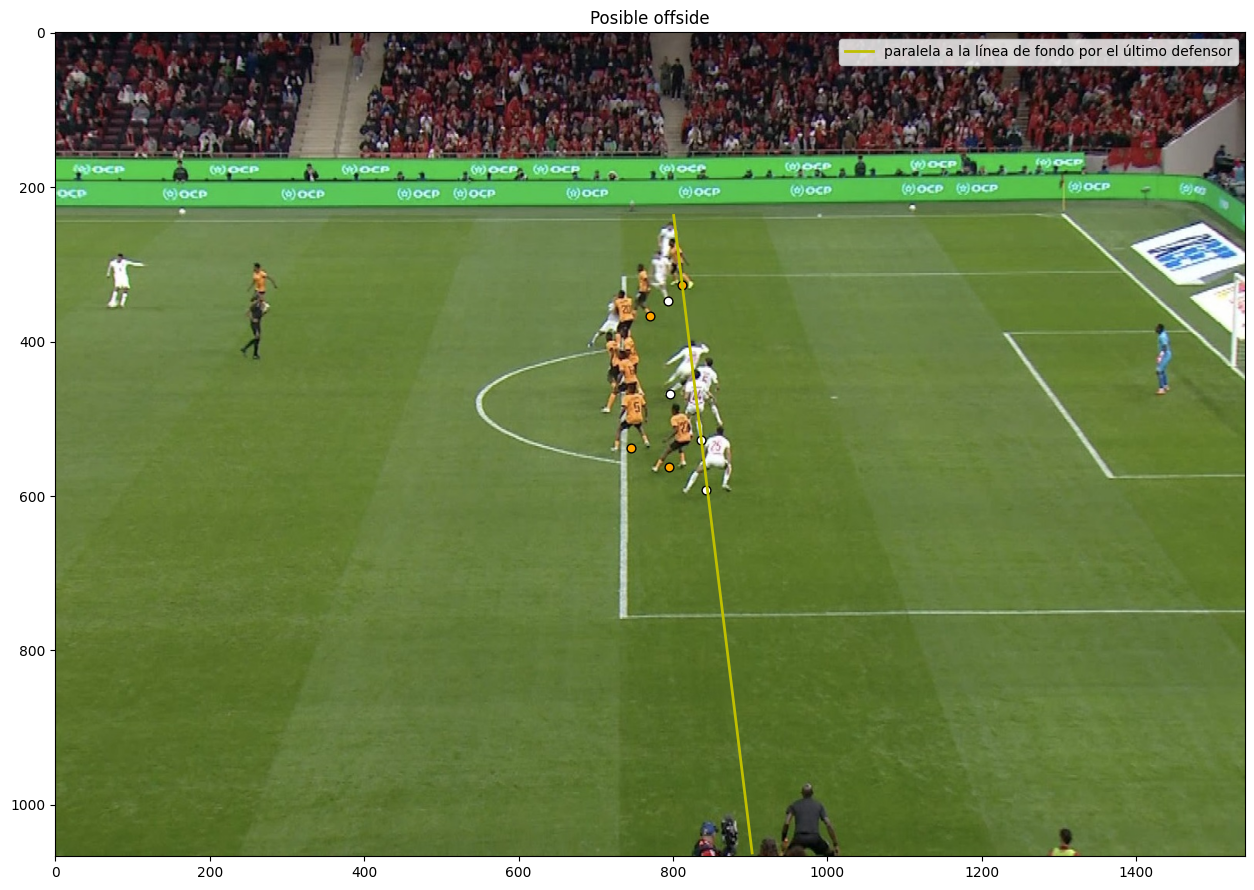

In [27]:
# ----------------- 4c) Recta de fuera de juego -----------------
# Píxel del pie de cada jugador (marcado a mano). Defensores = camiseta naranja; atacantes = camiseta blanca.
defensores = [("def. lejano (arriba)", 812, 327), ("def. (770,367)", 770, 367),
              ("def. n.° 5", 746, 538), ("def. n.° 27", 795, 562)]
atacantes = [("atac. (796,468)", 796, 468), ("atac. (843,592)", 843, 592),
             ("atac. (793,347)", 793, 347), ("atac. n.° 24 centro", 836, 528)]
arquero = ("arquero", 1432, 465)

H_off_inv = inversa(H_off)
def a_cancha(u, v):
    p = aplicar_homografia(H_off_inv, np.array([[float(u), float(v)]]))
    return p[0, 0], p[0, 1]

print("%-22s %8s %8s" % ("jugador", "U (m)", "V (m)"))
ult_def = None
for nombre, u, v in defensores:
    Uj, Vj = a_cancha(u, v)
    print("%-22s %8.2f %8.2f" % (nombre, Uj, Vj))
    if ult_def is None or Uj < ult_def[1]:
        ult_def = (nombre, Uj, u, v)          # el defensor más cercano a la línea de fondo (sin contar al arquero)
Ua, Va = a_cancha(arquero[1], arquero[2])
print("%-22s %8.2f %8.2f   (el arquero está más cerca de la línea: es el último adversario)" % (arquero[0], Ua, Va))
print("\nÚltimo defensor de campo (penúltimo adversario): %s a U = %.2f m" % (ult_def[0], ult_def[1]))

TOL = 0.15      # incertidumbre del clic: ~ +-10 px equivale a unos 15 cm en esta zona
print("\n%-22s %8s %22s" % ("atacante", "U (m)", "ventaja sobre la línea"))
for nombre, u, v in atacantes:
    Uj, Vj = a_cancha(u, v)
    ventaja = ult_def[1] - Uj           # > 0: está más cerca del arco que el defensor
    if ventaja > TOL:
        veredicto = "FUERA DE JUEGO"
    elif ventaja < -TOL:
        veredicto = "habilitado"
    else:
        veredicto = "en línea (no concluyente)"
    print("%-22s %8.2f %+10.2f m  -> %s" % (nombre, Uj, ventaja, veredicto))

# Recta paralela a la línea de fondo (U = const) por el pie del último defensor, proyectada a la foto
recta = recta_vertical(ult_def[1], 68.0, 400)
recta_foto = aplicar_homografia(H_off, recta)
alto, ancho = foto_off.shape[0], foto_off.shape[1]
dentro = []
for i in range(recta_foto.shape[0]):
    if 0 <= recta_foto[i, 0] < ancho and 0 <= recta_foto[i, 1] < alto:
        dentro.append([recta_foto[i, 0], recta_foto[i, 1]])
dentro = np.array(dentro)

fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(foto_off)
ax.plot(dentro[:, 0], dentro[:, 1], 'y-', linewidth=2, label="paralela a la línea de fondo por el último defensor")
for nombre, u, v in defensores:
    ax.scatter([u], [v], s=40, c='orange', edgecolors='k')
for nombre, u, v in atacantes:
    ax.scatter([u], [v], s=40, c='white', edgecolors='k')
ax.legend()
ax.set_title("Posible offside")
plt.tight_layout()
plt.show()

*(Valores calculados con test-fuera-de-juego.png; si se cambia por otra imagen, volver a correr y actualizar.)*

**Resultado c).** El último defensor de campo está en $U\approx14{,}65$ m. De los atacantes medidos, dos están claramente habilitados (0,5–0,7 m más atrás) y los otros dos quedan a **1–3 cm** de la línea. Esa diferencia es mucho menor que la incertidumbre de los clics (~15 cm): **con esta foto el resultado es "en línea", no concluyente a favor del fuera de juego.** La recta se ve inclinada porque las paralelas del piso convergen en un punto de fuga.

## Paso 8: resumen y límites

*(Valores calculados con las imágenes de prueba test-gol-enzo.png y test-fuera-de-juego.png; si se cambian por las del template, volver a correr y actualizar.)*

| Inciso | Resultado |
|---|---|
| a) | Enzo a ≈ 22,2 m de la línea del arco (±0,13 m por error de clic) |
| b) | Círculos de 1 m dibujados en 6 argentinos (se ven como elipses; el 6.º tiene los pies tapados y su posición es estimada) |
| c) | Último defensor en $U\approx14{,}65$ m; atacantes en línea (no concluyente) |

**Límites a mencionar en el informe:**
* Los píxeles están marcados **a mano** (error de 1–3 px ≈ unos centímetros).
* `H` solo vale para puntos **en el piso**: se usan los pies, no el cuerpo ni la pelota.
* Capturas de TV: compresión y posible distorsión de lente que el modelo pinhole no contempla.
* Offside: el reglamento considera cualquier parte del cuerpo con la que se pueda marcar (salvo brazos), no solo los pies; varios pies están tapados; y la posición relevante es la del instante del pase.